# Artificial Intelligence in Health Care - Exercise 2
## Convolutional Neural Networks for Image Classification

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel der Übung ist es ein CNN (Convolusional neural Network) zu trainieren um damit verschiedene histologische Bilder von Darmgewebe der passenden Kategorie (Darmschleimhaut, Tumorgewebe, Muskel, etc. ) zuordnen zu können.

In [12]:
#Imports and Configs
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


## Datenimport

In [13]:
import numpy as np
data = np.load("C:\\Users\\Marco\\Desktop\\Repos\\KIGW\\data\\path_train.npz")
print(list(data.keys()))

x_train, y_train = data["x_train"], data["y_train"]
x_val,   y_val   = data["x_val"],   data["y_val"]
x_test,  y_test  = data["x_test"],  data["y_test"]

#Kontrolle mit Angabenzettel Anzahl der Daten
print(x_train.shape, x_val.shape, x_test.shape)

['x_train', 'x_val', 'x_test', 'y_train', 'y_val', 'y_test']
(89996, 28, 28, 3) (10004, 28, 28, 3) (5744, 28, 28, 3)


### 1 Data Pre-Processing and Partitioning [2P]:


Make yourself familiar with the dataset by plotting one example image per class, arranged in
a figure of e.g. two rows, including class names and labels. Prepare class labels for the use
with a neural network and multi-class classification. The images are given in a range of [0, 255];
normalise them to [0, 1]. Report the class distribution of the training set. You will need it when
you interpret the confusion matrix in tasks 2 and 3.

#### Labels in 1D Array, Klassennamen festlegen 

In [14]:
#In 1D Arrays umwandeln, da Keras sonst Probleme hat
y_train = y_train.ravel(); y_val = y_val.ravel(); y_test = y_test.ravel()  

#Klassen aus Angabe übernommen, da die Klassenbezeichnungen nicht importiert wird wie bei medmnist
CLASSES = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]


#### Beispielbild pro Klasse

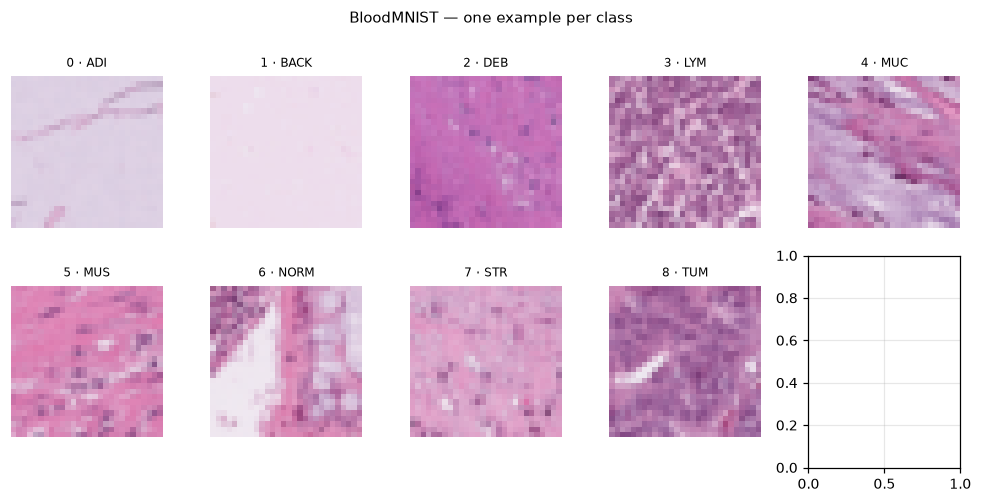

In [15]:

fig, axes = plt.subplots(2, 5, figsize=(9, 4.6))
for i, ax in enumerate(axes.ravel()):
    #if bedingung sonst gibt es einen index error, da es nur 9 Klassen gibt und wir 10 subplots haben
    if i < len(CLASSES):
        ax.imshow(x_train[np.where(y_train == i)[0][0]])
        ax.set_title(f"{i} · {CLASSES[i]}", fontsize=8)
        ax.axis("off")
fig.suptitle("BloodMNIST — one example per class", fontsize=10)
plt.tight_layout(); plt.show()


#### Klassenverteilung y_train

In [16]:
#Ausgabe der Datensatzgrößen und Klassenverteilung
print("train / val / test:", len(y_train), len(y_val), len(y_test))
print("image shape       :", x_train.shape[1:])
print("classes           :", len(CLASSES))
for i, c in enumerate(CLASSES):
    print(f"  {i}  {c:<28} {(y_train==i).sum():>6} {100*(y_train==i).mean():>5.1f}%")
print()
print("majority-class baseline accuracy: %.3f" % (np.bincount(y_test).max()/len(y_test)))

train / val / test: 89996 10004 5744
image shape       : (28, 28, 3)
classes           : 9
  0  ADI                            9366  10.4%
  1  BACK                           9509  10.6%
  2  DEB                           10360  11.5%
  3  LYM                           10401  11.6%
  4  MUC                            8006   8.9%
  5  MUS                           12182  13.5%
  6  NORM                           7886   8.8%
  7  STR                            9401  10.4%
  8  TUM                           12885  14.3%

majority-class baseline accuracy: 0.186


#### Bilder auf [0, 1] normalisieren

In [17]:
#auf 0-1 normalisieren wie bei NB3
x_train = x_train.astype("float32") / 255.0
x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

#Check min und max wert, sollte 0 und 1 sein
print(x_train.min(), x_train.max())   

0.0 1.0


#### Labels One-Hot-kodieren

In [ ]:
#prepare class labels for keras (one-hot encoding)
num_classes = len(CLASSES)

y_train_oh = keras.utils.to_categorical(y_train, num_classes)
y_val_oh   = keras.utils.to_categorical(y_val,   num_classes)
y_test_oh  = keras.utils.to_categorical(y_test,  num_classes)

#checken, ob die One-Hot-Encoding rihtig funktioniert hat, erste 3 labels ausgeben und die Form des Arrays
print(y_train[:3]); 
print(y_train_oh[:3]); 
print(y_train_oh.shape)

[0 4 7]
[[1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0.]]
(89996, 9)
